# 01. Exploración y descripción de HyKid

1. Estructura del dataset
2. Datos clínicos (Info.json)
3. Propiedades de las imágenes
4. Etiquetas de segmentación
5. Volúmenes
6. Visualización
7. Calidad de las segmentaciones automáticas
8. Hallazgos

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT))

import json
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from src.paths import RAW, SUBJECTS, OUTPUTS
from src.io import list_scans, load, load_seg, read_info, read_labels, find_ids, volumes_ml

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
OUTPUTS.mkdir(exist_ok=True)

## 1. Estructura del dataset

In [2]:
subjects = sorted(p for p in SUBJECTS.glob("sub_*") if p.is_dir())
all_scans = list_scans(require_gt=False)
scans = list_scans()

print("Sujetos:", len(subjects))
print("Scans:", len(all_scans))
print("Scans con gt:", len(scans))
print("Sujetos con más de un scan:", [s.name for s in subjects if len(list(s.glob("scan_*"))) > 1])

Sujetos: 48
Scans: 50
Scans con gt: 45
Sujetos con más de un scan: ['sub_019', 'sub_039']


In [3]:
expected = ["eT1W_FFE_AX.nii.gz", "eT1W_FFE_SAG.nii.gz", "eT1W_FFE_SVR.nii.gz",
            "segmentation/gt.nii.gz", "segmentation/synthseg.nii.gz",
            "segmentation/synthseg+ChP.nii.gz", "segmentation/spm12.nii.gz"]
avail = pd.DataFrame([{"scan": f"{s.parent.name}/{s.name}", **{f: (s / f).exists() for f in expected}} for s in all_scans])
avail[expected].sum().to_frame("archivos presentes")

,archivos presentes
eT1W_FFE_AX.nii.gz,50
eT1W_FFE_SAG.nii.gz,48
eT1W_FFE_SVR.nii.gz,50
segmentation/gt.nii.gz,45
segmentation/synthseg.nii.gz,45
segmentation/synthseg+ChP.nii.gz,45
segmentation/spm12.nii.gz,45


In [4]:
print("Archivos de un scan:")
for f in sorted(all_scans[0].rglob("*")):
    if f.is_file():
        print(f"  {f.relative_to(all_scans[0])}  ({f.stat().st_size / 1e6:.1f} MB)")

Archivos de un scan:
  eT1W_FFE_AX.nii.gz  (2.6 MB)
  eT1W_FFE_SAG.nii.gz  (4.1 MB)
  eT1W_FFE_SVR.nii.gz  (34.8 MB)
  manifest.csv  (0.0 MB)
  segmentation\gt.nii.gz  (0.3 MB)
  segmentation\manifest.csv  (0.0 MB)
  segmentation\spm12.nii.gz  (1.8 MB)
  segmentation\synapse_metadata_manifest.tsv  (0.0 MB)
  segmentation\synthseg+ChP.nii.gz  (0.4 MB)
  segmentation\synthseg.nii.gz  (0.7 MB)
  synapse_metadata_manifest.tsv  (0.0 MB)


## 2. Datos clínicos (Info.json)

In [5]:
print(json.dumps(read_info(all_scans[0]), indent=2, ensure_ascii=False)[:2500])

{
  "Imaging": {
    "etiology": {
      "type": "tumor",
      "basis": "松果体区见一不规则混杂信号肿块，注射对比剂后，肿块明显强化；松果体肿瘤部分切除术后"
    },
    "classification": {
      "type": "梗阻性",
      "obstruction_location": "导水管",
      "basis": "松果体区肿块压迫导水管"
    },
    "imaging_features": {
      "brain_structure_features": "导水管、侧脑室、第四脑室、松果体区、脑外间隙",
      "other_features": "左侧额部脑外间隙积气，右侧脑室内引流管置入，上颌窦及蝶窦长T2信号，筛窦及蝶窦粘膜增厚",
      "basis": "左侧额部脑外间隙中见气体影，松果体区见一不规则混杂信号肿块，注射对比剂后，肿块明显强化，肿块压迫导水管；双侧侧脑室未见明显扩张，右侧脑室内见引流管置入中；第四脑室及未见扩大及受压推移；右侧上颌窦及蝶窦内长T2信号；双侧筛窦及蝶窦内可见粘膜增厚"
    },
    "ventricular_changes": {
      "trend": "减小",
      "basis": "松果体区见一不规则混杂信号肿块较前（2019.11.14）明显缩小；对比（2020.02.17）老片，基本相仿"
    },
    "severity": {
      "level": "减轻",
      "basis": "脑积水较前明显好转；脑积水已不明显"
    }
  },
  "Ward_round": {
    "symptoms": {
      "basis": "头痛呕吐伴视物重影2周余；双眼视物有重影，中间明显"
    },
    "postoperative_complications": {
      "vp_shunt_complications": "其他",
      "symptom_description": "术后气胸、气栓、纵隔血肿、出血、血肿；导管移位、扭曲、脱落、破坏、渗漏、纤维蛋白鞘形成、血栓形成、

In [6]:
clin = pd.json_normalize([{"subject": s.name, **(json.loads((s / "Info.json").read_text(encoding="utf-8")) if (s / "Info.json").exists() else {})} for s in subjects])
print(clin.shape)
clin.head()

(48, 31)


,subject,Imaging.etiology.type,Imaging.etiology.basis,Imaging.classification.type,Imaging.classification.obstruction_location,Imaging.classification.basis,Imaging.imaging_features.brain_structure_features,Imaging.imaging_features.other_features,Imaging.imaging_features.basis,Imaging.ventricular_changes.trend,Imaging.ventricular_changes.basis,Imaging.severity.level,Imaging.severity.basis,Ward_round.symptoms.basis,Ward_round.postoperative_complications.vp_shunt_complications,Ward_round.postoperative_complications.symptom_description,Ward_round.postoperative_complications.basis,Surgery.surgery_type.type,Surgery.surgery_type.surgery_name,Surgery.surgery_type.basis,Surgery.shunt_system_details.shunt_type,Surgery.shunt_system_details.shunt_location,Surgery.shunt_system_details.proximal_catheter_tip_location,Surgery.shunt_system_details.basis,Surgery.pressure_data.initial_csf_pressure.value,Surgery.pressure_data.initial_csf_pressure.unit,Surgery.pressure_data.shunt_pressure_level,Surgery.pressure_data.pressure_range,Surgery.pressure_data.basis,Surgery.pressure_data.initial_csf_pressure,Surgery.pressure_data.initial_csf_pressure.basis
0,sub_001,tumor,松果体区见一不规则混杂信号肿块，注射对比剂后，肿块明显强化；松果体肿瘤部分切除术后,梗阻性,导水管,松果体区肿块压迫导水管,导水管、侧脑室、第四脑室、松果体区、脑外间隙,左侧额部脑外间隙积气，右侧脑室内引流管置入，上颌窦及蝶窦长T2信号，筛窦及蝶窦粘膜增厚,左侧额部脑外间隙中见气体影，松果体区见一不规则混杂信号肿块，注射对比剂后，肿块明显强化，肿块压迫导水管；双侧侧脑室未见明显扩张，右侧脑室内见引流管置入中...,减小,松果体区见一不规则混杂信号肿块较前（2019.11.14）明显缩小；对比（2020.02.17）老片，基本相仿,减轻,脑积水较前明显好转；脑积水已不明显,头痛呕吐伴视物重影2周余；双眼视物有重影，中间明显,其他,术后气胸、气栓、纵隔血肿、出血、血肿；导管移位、扭曲、脱落、破坏、渗漏、纤维蛋白鞘形成、血栓形成、上腔静脉阻塞综合征、导管阻塞、感染：局部感染、全身感染...,术后风险告知家长：术后气胸、气栓、纵隔血肿、出血、血肿；导管移位、扭曲、脱落、破坏、渗漏、纤维蛋白鞘形成、血栓形成、上腔静脉阻塞综合征、导管阻塞、感染：...,VP分流,侧脑室腹腔分流术,拟行手术名称: 侧脑室腹腔分流术,Programmable,脑室-腹腔分流,枕角,用脑室穿刺针于侧脑室后角穿刺，入颅内约5cm有突破感...连接美敦力可调压分流管阀门,25.0,cmH2O,2.0,60-80mmH2O,压力高，初测大于25cmH2O。术后压力为2.0,NaN,NaN
1,sub_002,hemorrhage-related,诊断名称：颅内出血后脑积水,梗阻性,四脑室,左侧小脑半球及枕部颅板下可见囊性长T1长T2信号影，似与四脑室相通；后颅窝及枕部囊性灶，与四脑室相通,四脑室、右侧侧脑室、脑干、脑室周围白质,左侧后颅窝囊性灶、右侧额叶条状异常信号、脑干受压变形且较细小、脑室旁间质性水肿,左侧小脑半球及枕部颅板下可见囊性长T1长T2信号影，似与四脑室相通，囊性灶周围小脑实质FLAIR序列信号偏高，脑干受压变形、细小；右侧额叶可见条状长T1...,稳定,以上改变较前片（2021.10.28）变化不明显,稳定,以上改变较前片（2021.10.28）变化不明显,主诉：行走不稳1周余；入院查体：站立不稳易摔倒；现病史：患儿出现行走不稳，易摔倒,感染,血管畸形术后，脑积水合并脑膜炎，目前体温和外周血炎症指标正常3周以上，脑脊液多次检查：细胞数50个以下，糖2.0以上，蛋白1g左右，培养多次阴性，病原不...,查房记录（2021-11-23）: 感染科会诊示：病史敬悉 血管畸形术后，脑积水合并脑膜炎，目前体温和外周血炎症指标正常3周以上，脑脊液多次检查：细胞数...,ETV,神经导航下神经内镜下三脑室底造瘘术,手术名称: 神经导航下神经内镜下三脑室底造瘘术,None,None,None,无分流相关描述，仅行三脑室底造瘘术,NaN,NaN,None,NaN,报告中未提及脑脊液压力数值及单位，也未涉及分流管压力设置,NaN,NaN
2,sub_003,tumor,右侧小脑半球肿块，内见结节状强化-胶质瘤考虑；右侧小脑半球病变术后复查,梗阻性,第四脑室及中脑导水管,第四脑室及中脑导水管受压变窄,第四脑室、中脑导水管、侧脑室、第三脑室、脑干、双侧丘脑、小脑扁桃体、小脑蚓部,幕上脑积水伴脑室旁间质性水肿、引流管影、术区脑实质肿胀、出血、水肿、枕部头皮软组织肿胀,幕上脑室扩张，右侧侧脑室可见一引流管影，双侧侧脑室旁白质及引流管走行区域脑实质呈长T2信号改变；第四脑室及中脑导水管受压变窄；小脑扁桃体下缘低于枕骨大孔...,减小,病变较前片（2021.03.30）略缩小；右侧小脑半球、脑干及丘脑病变较前片（2021-08-25）范围稍有缩小,稳定,幕上脑积水伴脑室旁间质性水肿，较前片大致相仿,因呕吐1月余入院；4天前出现呕吐，3-4次/天，非喷射性；GCS评分10分，嗜睡；查体：GCS评分12分，精神可，双侧瞳孔等大等圆，光反应灵敏，四肢肌力...,分流管阻塞,6月前再次因“分流管障碍”中断放疗，并在我院住院治疗，行“脑室腹腔分流管调整术”。,6月前再次因“分流管障碍”中断放疗，并在我院住院治疗，行“脑室腹腔分流管调整术”，术后压力调节在12。,VP分流,侧脑室-腹腔分流术,手术名称: 侧脑室-腹腔分流术,Fixed,脑室-腹腔分流,右侧脑室后角,右侧脑室后角穿刺，入颅内约6cm，有澄清脑脊液流出；固定头部引流管并连接分流阀门,15.0,cmH2O,None,40-60mmH2O,压力超过15cm水柱；术后压力为20,NaN,NaN
3,sub_004,congenital,小脑蚓部静脉畸形，引流血管粗大，走行于中脑导水管旁；左侧小脑半球发育性静脉畸形；小脑蚓部发育性静脉畸形。,梗阻性,中脑导水管,幕上脑室明显扩张；中脑导水管扩张，内信号不均匀；压迫中脑导水管可能；中脑导水管受压变窄；动态序列未见高信号脑脊液影通过。,侧脑室、第三脑室、中脑导水管、四叠体区、小脑蚓部、胼胝体,双侧侧脑室旁白质斑片状长T1长T2信号影；中脑导水管扩张且信号不均；粗大流空血管影伴海蛇头征；引流血管向上走行于中脑导水管旁；硬膜外血肿及硬膜下积血（术...,幕上脑室明显扩张；双侧侧脑室体部室壁欠光整；中脑导水管扩张，内信号不均匀；小脑蚓部见一粗大流空血管影，周围见海蛇头征；引流血管向上走行于中脑导水管旁；左...,稳定,与前片大致相仿；脑积水征象较前略改善；脑积水征象较前大致相仿；脑积水征象较前稳定。,稳定,与前片大致相仿；脑积水征象较前稳定；幕上脑室扩张情况同前；脑积水征象较前无明显变化。,体温最高39℃，伴头痛...2天前开始恶心呕吐...患儿今因步行时易摔跤予以康复评估,感染,发热10天，伴头痛、呕吐，有V-P分流史,1、颅内感染：患儿发热10天，伴头痛、呕吐，有V-P分流史，需警惕，查脑脊液检查助诊,VP分流,"侧脑室腹腔内分流管取出术, 神经导航辅助神经内镜下三脑室底造瘘术+侧脑室-腹腔分流管腹腔端取出术",手术名称中包含'侧脑室腹腔内分流管取出术'和'侧脑室-腹腔分流管腹腔端取出术',Programmable,脑室-腹腔分流,额角,手术经过中提到'左侧冠状缝前额部作一弧形切口'，提示脑室端置入位置为额角；术后调压为2.5'提示使用可调压阀,NaN,NaN,2.5,60-80mmH2O,手术经过中提到'术后调压为2.5'，根据临床常规，可调压阀档位2.5对应压力范围为60-80mmH2O,NaN,NaN
4,sub_005,tumor,鞍上见形态不规则等T1稍长T2信号影，其内可见少许囊性信号影...增强后肿块呈显著不均匀强化,梗阻性,三脑室,肿瘤侵入三脑室可能,鞍上、三脑室、侧脑室、第三脑室、第四脑室、导水管,右侧侧脑室内可见引流管，

In [7]:
missing = clin.isna().mean().sort_values(ascending=False)
missing[missing > 0].to_frame("% faltante").style.format("{:.0%}")

,% faltante
Surgery.pressure_data.initial_csf_pressure,100%
Surgery.pressure_data.initial_csf_pressure.basis,98%
Surgery.pressure_data.shunt_pressure_level,65%
Surgery.pressure_data.initial_csf_pressure.value,56%
Surgery.pressure_data.initial_csf_pressure.unit,56%
Ward_round.postoperative_complications.symptom_description,50%
Surgery.pressure_data.pressure_range,48%
Ward_round.postoperative_complications.basis,44%
Surgery.shunt_system_details.basis,42%
Surgery.surgery_type.type,42%


In [8]:
cat_cols = [c for c in clin.columns if c != "subject" and clin[c].astype(str).nunique() <= 8]
for c in cat_cols:
    print(f"\n{c}")
    print(clin[c].astype(str).value_counts().to_string())


Imaging.etiology.type
Imaging.etiology.type
tumor                 23
congenital            10
hemorrhage-related     5
post-traumatic         4
infection              3
idiopathic             3

Imaging.classification.type
Imaging.classification.type
梗阻性    46
交通性     2

Imaging.ventricular_changes.trend
Imaging.ventricular_changes.trend
稳定    32
减小    14
增大     2

Imaging.severity.level
Imaging.severity.level
稳定    32
减轻    12
加重     4

Ward_round.postoperative_complications.vp_shunt_complications
Ward_round.postoperative_complications.vp_shunt_complications
其他       8
感染       8
None     7
分流管阻塞    4
过度引流     2

Surgery.surgery_type.type
Surgery.surgery_type.type
VP分流    19
ETV      6
None     3

Surgery.shunt_system_details.shunt_type
Surgery.shunt_system_details.shunt_type
Programmable    17
None             9
Fixed            2

Surgery.shunt_system_details.shunt_location
Surgery.shunt_system_details.shunt_location
脑室-腹腔分流               18
None                   9
脑室腹腔分流, 右侧侧脑室-腹

In [10]:
num_cols = [c for c in clin.columns if c != "subject" and pd.to_numeric(clin[c], errors="coerce").notna().mean() > 0.8]
if num_cols:
    display(clin[num_cols].apply(pd.to_numeric, errors="coerce").describe().round(2))
else:
    print("Sin columnas numéricas. Columnas:")
    print(clin.dtypes.to_string())

Sin columnas numéricas. Columnas:
subject                                                              str
Imaging.etiology.type                                                str
Imaging.etiology.basis                                               str
Imaging.classification.type                                          str
Imaging.classification.obstruction_location                          str
Imaging.classification.basis                                         str
Imaging.imaging_features.brain_structure_features                    str
Imaging.imaging_features.other_features                              str
Imaging.imaging_features.basis                                       str
Imaging.ventricular_changes.trend                                    str
Imaging.ventricular_changes.basis                                    str
Imaging.severity.level                                               str
Imaging.severity.basis                                               str
Ward_round.sympto

C:\Users\Usuario\AppData\Local\Temp\ipykernel_24772\3524675028.py:9: UserWarning: Glyph 26775 (\N{CJK UNIFIED IDEOGRAPH-6897}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_24772\3524675028.py:9: UserWarning: Glyph 38459 (\N{CJK UNIFIED IDEOGRAPH-963B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_24772\3524675028.py:9: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_24772\3524675028.py:9: UserWarning: Glyph 20132 (\N{CJK UNIFIED IDEOGRAPH-4EA4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_24772\3524675028.py:9: UserWarning: Glyph 36890 (\N{CJK UNIFIED IDEOGRAPH-901A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_24772\3524675028.py:9: UserWarning: Glyph 31

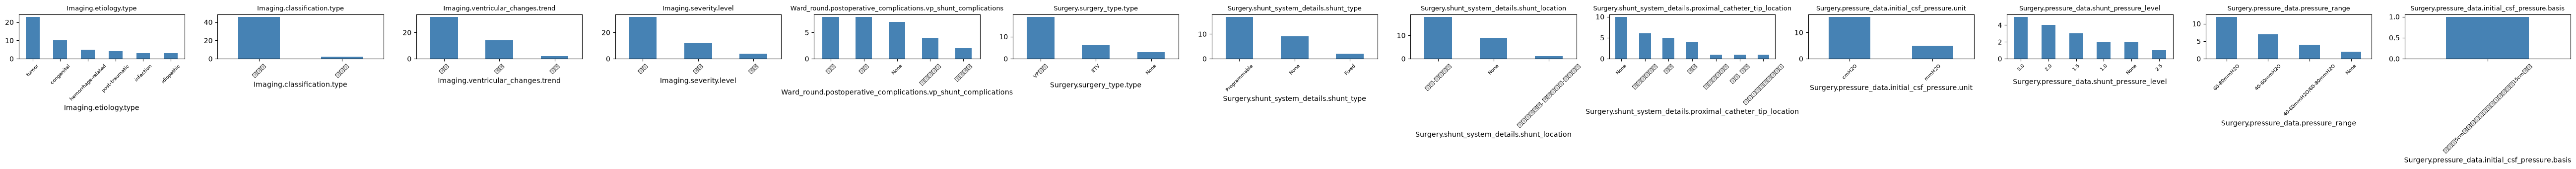

In [13]:
cat_cols = [c for c in cat_cols if clin[c].dropna().size]
n = len(cat_cols)
if n:
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 3.5), squeeze=False)
    for ax, c in zip(axes[0], cat_cols):
        clin[c].dropna().astype(str).value_counts().plot.bar(ax=ax, color="steelblue")
        ax.set_title(c, fontsize=9)
        ax.tick_params(axis="x", labelsize=7, rotation=45)
    plt.tight_layout()
    plt.show()

## 3. Propiedades de las imágenes

In [14]:
rows = []
for s in all_scans:
    for name in ["eT1W_FFE_AX", "eT1W_FFE_SAG", "eT1W_FFE_SVR"]:
        p = s / f"{name}.nii.gz"
        if p.exists():
            img = nib.load(p)
            rows.append({"scan": f"{s.parent.name}/{s.name}", "imagen": name.split("_")[-1],
                         "shape": img.shape[:3], "voxel_mm": tuple(round(float(z), 2) for z in img.header.get_zooms()[:3]),
                         "orient": "".join(nib.aff2axcodes(img.affine)), "dtype": img.get_data_dtype().name})
props = pd.DataFrame(rows)
props.head(9)

,scan,imagen,shape,voxel_mm,orient,dtype
0,sub_001/scan_01,AX,"(512, 512, 18)","(0.45, 0.45, 7.5)",LPS,uint16
1,sub_001/scan_01,SAG,"(512, 512, 18)","(0.45, 0.45, 7.0)",PIR,uint16
2,sub_001/scan_01,SVR,"(257, 254, 226)","(1.0, 1.0, 1.0)",PIR,float32
3,sub_002/scan_01,AX,"(512, 512, 20)","(0.45, 0.45, 7.0)",LPS,uint16
4,sub_002/scan_01,SAG,"(512, 512, 18)","(0.45, 0.45, 7.0)",PIR,uint16
5,sub_002/scan_01,SVR,"(252, 277, 240)","(1.0, 1.0, 1.0)",LPS,float32
6,sub_003/scan_01,AX,"(512, 512, 20)","(0.45, 0.45, 7.0)",LPS,uint16
7,sub_003/scan_01,SAG,"(512, 512, 18)","(0.45, 0.45, 7.0)",PIR,uint16
8,sub_003/scan_01,SVR,"(252, 256, 236)","(1.0, 1.0, 1.0)",LPS,float32


In [15]:
for k, g in props.groupby("imagen"):
    print(f"\n{k}")
    print("  shapes:", g["shape"].value_counts().head(5).to_dict())
    print("  voxel:", g["voxel_mm"].value_counts().head(5).to_dict())
    print("  orientación:", g["orient"].value_counts().to_dict())


AX
  shapes: {(512, 512, 20): 21, (512, 512, 18): 9, (672, 672, 20): 4, (512, 512, 21): 3, (512, 512, 22): 2}
  voxel: {(0.45, 0.45, 7.0): 27, (0.45, 0.45, 7.5): 7, (0.34, 0.34, 7.5): 4, (0.34, 0.34, 7.0): 2, (0.43, 0.43, 8.2): 2}
  orientación: {'LPS': 49, 'LIP': 1}

SAG
  shapes: {(512, 512, 18): 34, (512, 512, 20): 6, (480, 480, 18): 3, (448, 448, 18): 3, (448, 448, 21): 1}
  voxel: {(0.45, 0.45, 7.0): 34, (0.45, 0.45, 7.3): 4, (0.45, 0.45, 6.0): 2, (0.44, 0.44, 6.5): 1, (0.42, 0.42, 7.0): 1}
  orientación: {'PIR': 48}

SVR
  shapes: {(265, 252, 226): 2, (262, 252, 240): 2, (252, 256, 250): 2, (254, 252, 226): 2, (257, 254, 226): 1}
  voxel: {(1.0, 1.0, 1.0): 50}
  orientación: {'LPS': 33, 'PIR': 17}


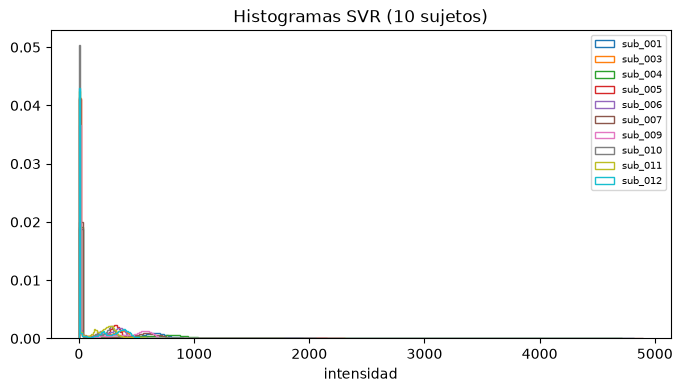

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
for s in scans[:10]:
    v, _ = load(s / "eT1W_FFE_SVR.nii.gz")
    v = v[v > np.percentile(v, 20)]
    ax.hist(v, bins=150, histtype="step", density=True, label=s.parent.name)
ax.set_xlabel("intensidad")
ax.set_title("Histogramas SVR (10 sujetos)")
ax.legend(fontsize=7)
plt.show()

## 4. Etiquetas de segmentación

In [17]:
labels = read_labels()
vent_ids = find_ids(labels, "ventric")
cp_ids = find_ids(labels, "choroid", "plexus")
print("Etiquetas:", labels)
print("Ventrículo:", vent_ids, "| Plexo coroideo:", cp_ids)

Etiquetas: {}
Ventrículo: [] | Plexo coroideo: []


In [18]:
gt0, _ = load_seg(scans[0] / "segmentation" / "gt.nii.gz")
ss0, _ = load_seg(scans[0] / "segmentation" / "synthseg.nii.gz")
print("Valores en gt:", np.unique(gt0).tolist())
print("Valores en synthseg:", np.unique(ss0).tolist())

Valores en gt: [0, 1, 2, 3, 4, 5]
Valores en synthseg: [0, 2, 3, 4, 5, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 24, 26, 28, 41, 42, 43, 44, 46, 47, 49, 50, 51, 52, 53, 54, 58, 60]


## 5. Volúmenes (gt)

In [19]:
rows = []
for s in scans:
    seg, z = load_seg(s / "segmentation" / "gt.nii.gz")
    rows.append({"subject": s.parent.name, "scan": s.name,
                 **{labels.get(i, f"label_{i}"): v for i, v in volumes_ml(seg, z).items()}})
vols = pd.DataFrame(rows)
vol_cols = [c for c in vols.columns if c not in ("subject", "scan")]
vols.to_csv(OUTPUTS / "volumes_gt.csv", index=False)
vols[vol_cols].describe().round(1)

,label_1,label_2,label_3,label_4,label_5
count,45.0,45.0,45.0,45.0,45.0
mean,272.5,616.2,423.4,102.6,3.2
std,47.8,100.9,86.8,92.6,1.7
min,151.4,376.6,207.5,10.4,0.5
25%,237.5,572.8,386.3,25.3,1.8
50%,263.8,604.3,415.9,74.5,3.2
75%,300.7,658.3,450.9,146.9,4.1
max,373.3,1006.0,780.0,385.7,7.6


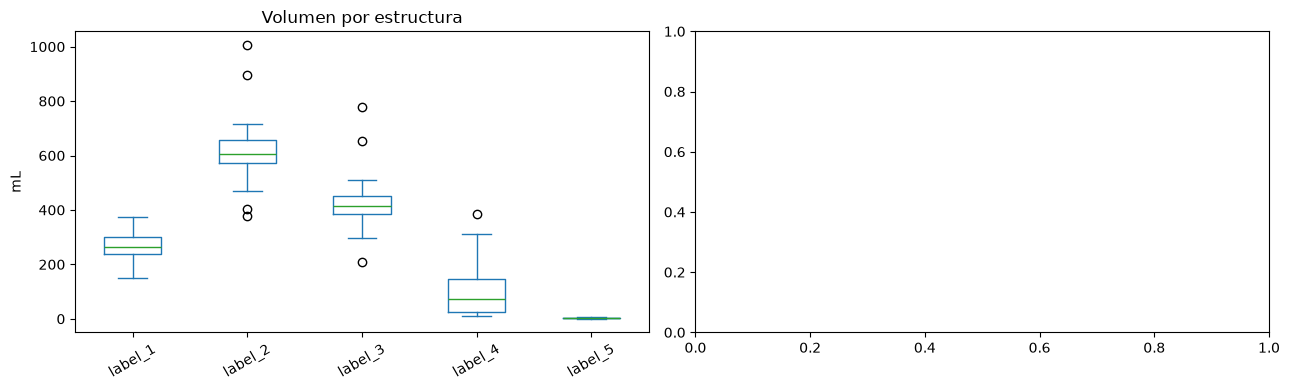

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vols[vol_cols].plot.box(ax=axes[0])
axes[0].set_ylabel("mL")
axes[0].set_title("Volumen por estructura")
axes[0].tick_params(axis="x", rotation=30)
if vent_ids:
    vname = labels[vent_ids[0]]
    vols[vname].sort_values().reset_index(drop=True).plot.bar(ax=axes[1], color="steelblue")
    axes[1].set_title(f"{vname} por caso (ordenado)")
    axes[1].set_xticks([])
plt.tight_layout()
plt.show()

In [21]:
age_col = next((c for c in clin.columns if "age" in c.lower() or "edad" in c.lower()), None)
if age_col and vent_ids:
    m = vols.merge(clin[["subject", age_col]], on="subject")
    m[age_col] = pd.to_numeric(m[age_col], errors="coerce")
    plt.scatter(m[age_col], m[labels[vent_ids[0]]])
    plt.xlabel(age_col)
    plt.ylabel("volumen ventricular (mL)")
    plt.show()
else:
    print("No se encontró columna de edad; revisa clin.columns")

No se encontró columna de edad; revisa clin.columns


## 6. Visualización

In [22]:
ids = sorted({int(i) for i in np.unique(gt0) if i})
cmap = ListedColormap([plt.cm.tab10(i % 10) for i in range(max(ids) + 1)])

def overlay(ax, vol, seg, axis, idx, title=""):
    take = lambda a: np.rot90(np.take(a, idx, axis=axis))
    ax.imshow(take(vol), cmap="gray", vmax=np.percentile(vol, 99.5))
    if seg is not None:
        ax.imshow(np.ma.masked_equal(take(seg), 0), cmap=cmap, alpha=0.45, vmin=0, vmax=max(ids))
    ax.set_title(title, fontsize=9)
    ax.axis("off")

def vent_slice(seg, axis):
    m = np.isin(seg, vent_ids) if vent_ids else seg > 0
    counts = m.sum(axis=tuple(i for i in range(3) if i != axis))
    return int(np.argmax(counts))

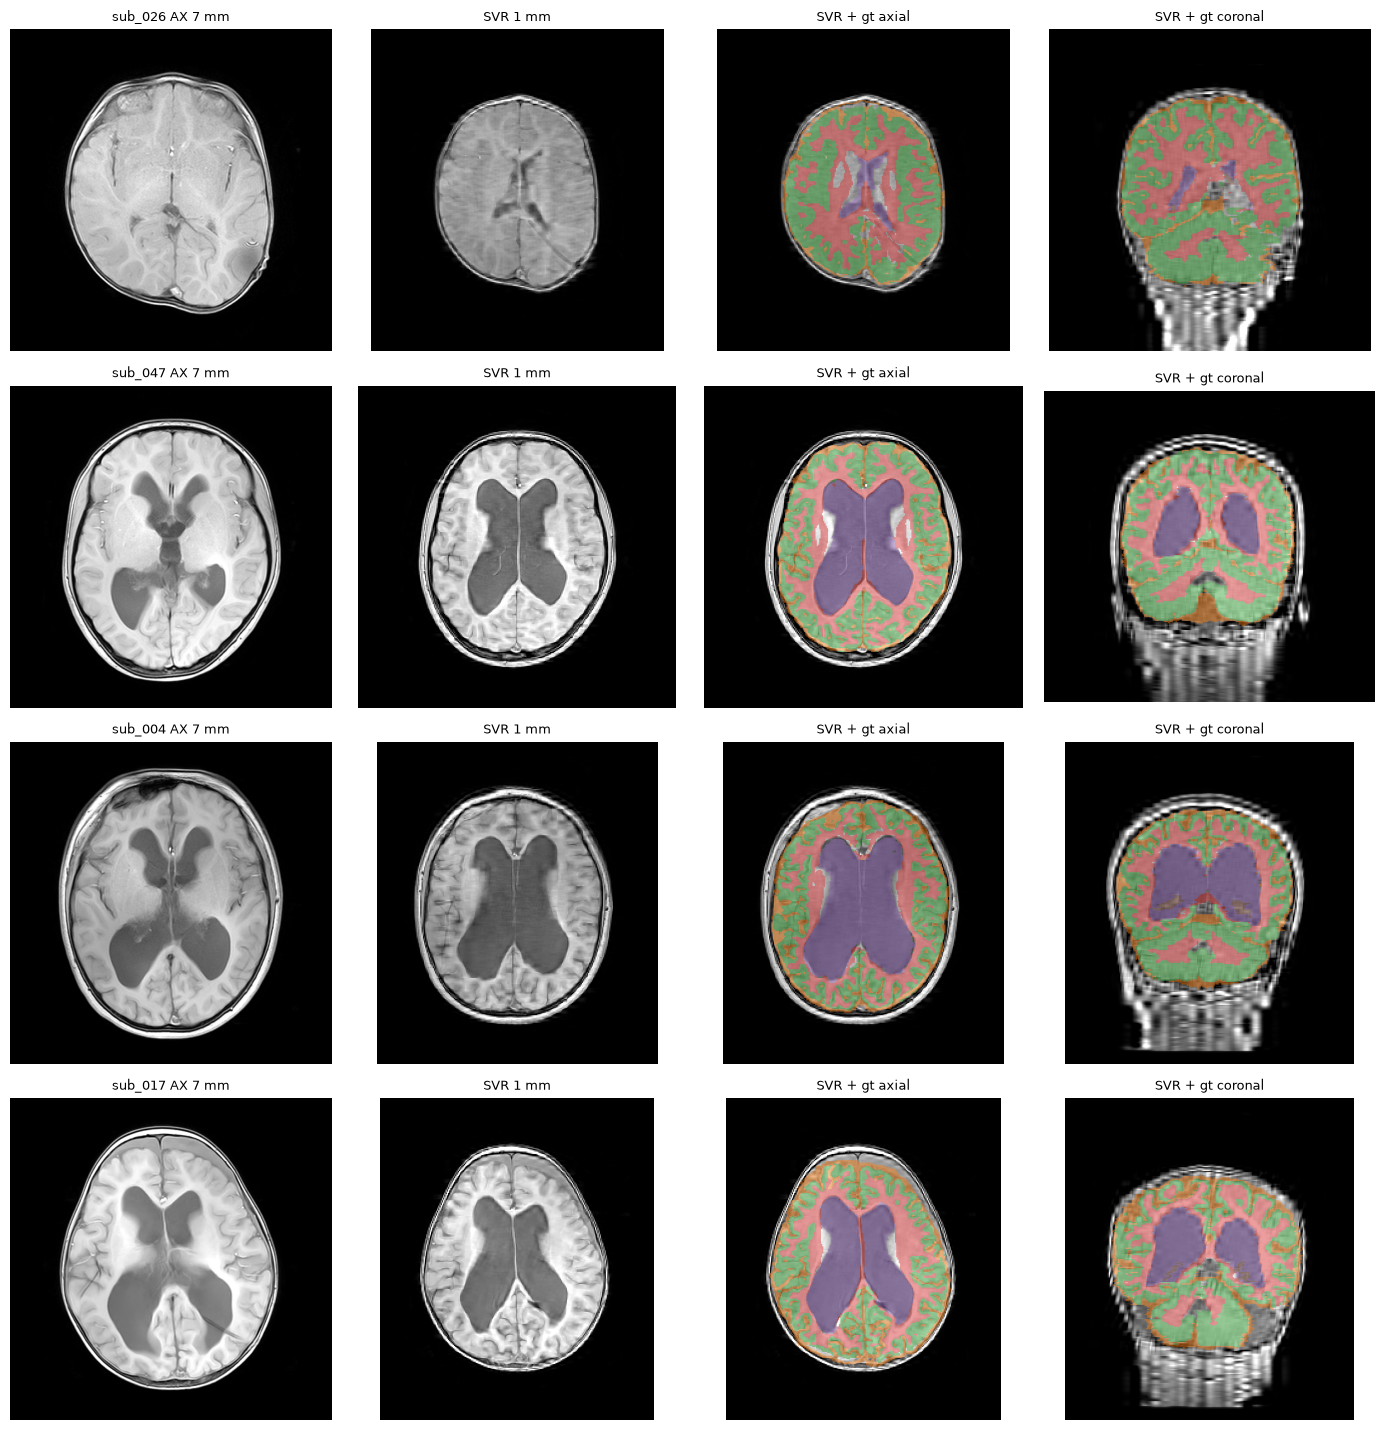

In [23]:
order = vols.sort_values(vol_cols[0] if not vent_ids else labels[vent_ids[0]])
picks = order.iloc[np.linspace(0, len(order) - 1, min(4, len(order))).astype(int)]

fig, axes = plt.subplots(len(picks), 4, figsize=(14, 3.6 * len(picks)), squeeze=False)
for row, (_, r) in zip(axes, picks.iterrows()):
    s = SUBJECTS / r["subject"] / r["scan"]
    ax_v, _ = load(s / "eT1W_FFE_AX.nii.gz")
    svr, _ = load(s / "eT1W_FFE_SVR.nii.gz")
    gt, _ = load_seg(s / "segmentation" / "gt.nii.gz")
    z = vent_slice(gt, 2)
    overlay(row[0], ax_v, None, 2, ax_v.shape[2] // 2, f"{r['subject']} AX 7 mm")
    overlay(row[1], svr, None, 2, z, "SVR 1 mm")
    overlay(row[2], svr, gt, 2, z, "SVR + gt axial")
    overlay(row[3], svr, gt, 1, vent_slice(gt, 1), "SVR + gt coronal")
plt.tight_layout()
plt.show()

## 7. Calidad de las segmentaciones automáticas (ventrículo)
En SynthSeg los ventrículos laterales son 4, 5, 43, 44.

In [24]:
SS_VENT = [4, 5, 43, 44]

def dice(a, b):
    d = a.sum() + b.sum()
    return 2 * (a & b).sum() / d if d else np.nan

res = []
for s in scans:
    p = s / "segmentation" / "synthseg.nii.gz"
    if not p.exists() or not vent_ids:
        continue
    g = np.isin(np.asarray(nib.load(s / "segmentation" / "gt.nii.gz").dataobj).astype(int), vent_ids)
    a = np.isin(np.asarray(nib.load(p).dataobj).astype(int), SS_VENT)
    if g.shape == a.shape:
        res.append({"subject": s.parent.name, "dice": dice(g, a), "vol_gt": g.sum() / 1000, "vol_ss": a.sum() / 1000})
q = pd.DataFrame(res)
if len(q):
    print(f"Dice SynthSeg vs gt: {q.dice.mean():.3f} +/- {q.dice.std():.3f}  (paper: 0.866 +/- 0.202)")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].scatter(q.vol_gt, q.dice)
    axes[0].set_xlabel("volumen gt (mL)")
    axes[0].set_ylabel("Dice")
    axes[1].scatter(q.vol_gt, q.vol_ss)
    lim = [0, max(q.vol_gt.max(), q.vol_ss.max()) * 1.05]
    axes[1].plot(lim, lim, "k--", lw=1)
    axes[1].set_xlabel("volumen gt (mL)")
    axes[1].set_ylabel("volumen SynthSeg (mL)")
    plt.tight_layout()
    plt.show()
    q.sort_values("dice").head()

## 8. Hallazgos

Completar después de correr:

- Nº de sujetos, scans y archivos faltantes:
- Variables clínicas útiles y % faltante:
- Resolución original vs SVR:
- Rango de volumen ventricular:
- Dice SynthSeg y en qué casos falla:
- Decisión de alcance: